In [43]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("messy_customer_churn.csv")

In [44]:
df.head(8)

,CustomerID,Age,MonthlyCharges,TenureMonths,Contract,SupportCalls,PaymentMethod,Churn
0,1001,25.0,29.99,2,Month-to-month,5,Card,Yes
1,1002,34.0,65.50,24,One year,2,Bank transfer,No
2,1003,45.0,80.00,48,Two year,1,Card,No
3,1004,NaN,45.25,12,Month-to-month,4,Cash,Yes
4,1005,29.0,55.00,5,One year,3,Card,No
5,1005,29.0,55.00,5,One year,3,Card,No
6,1007,52.0,95.00,60,Two year,0,Bank transfer,No
7,1008,41.0,NaN,18,Month-to-month,6,Card,Yes


In [45]:
df.shape

(30, 8)

In [46]:
df.columns

Index(['CustomerID', 'Age', 'MonthlyCharges', 'TenureMonths', 'Contract',
       'SupportCalls', 'PaymentMethod', 'Churn'],
      dtype='object')

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   CustomerID      30 non-null     int64  
 1   Age             28 non-null     float64
 2   MonthlyCharges  28 non-null     float64
 3   TenureMonths    30 non-null     int64  
 4   Contract        30 non-null     object 
 5   SupportCalls    30 non-null     int64  
 6   PaymentMethod   30 non-null     object 
 7   Churn           30 non-null     object 
dtypes: float64(2), int64(3), object(3)
memory usage: 2.0+ KB


In [48]:
df.isnull().sum()
df.isna().any()

CustomerID        False
Age                True
MonthlyCharges     True
TenureMonths      False
Contract          False
SupportCalls      False
PaymentMethod     False
Churn             False
dtype: bool

In [49]:
df.describe()

,CustomerID,Age,MonthlyCharges,TenureMonths,SupportCalls
count,30.000000,28.000000,28.000000,30.000000,30.000000
mean,1015.466667,41.357143,98.651071,26.933333,3.000000
std,8.842426,23.320972,197.362677,22.880399,2.165561
min,1001.000000,23.000000,25.000000,1.000000,0.000000
25%,1008.250000,29.750000,47.312500,8.250000,1.000000
50%,1015.500000,36.500000,61.000000,20.000000,3.000000
75%,1022.750000,44.250000,77.750000,43.000000,4.750000
max,1030.000000,150.000000,1100.000000,72.000000,7.000000


In [50]:
df.duplicated().sum()

np.int64(1)

In [51]:
df[(df["Age"] < 0) | (df["Age"] > 100)]

,CustomerID,Age,MonthlyCharges,TenureMonths,Contract,SupportCalls,PaymentMethod,Churn
9,1010,150.0,70.0,24,Two year,1,Card,Yes


In [52]:
df.isnull().sum()/len(df) * 100

CustomerID        0.000000
Age               6.666667
MonthlyCharges    6.666667
TenureMonths      0.000000
Contract          0.000000
SupportCalls      0.000000
PaymentMethod     0.000000
Churn             0.000000
dtype: float64

In [53]:
skewness = df["Age"].skew()
print(skewness)

3.9816259390477544


In [54]:
print(df.isnull().sum())
print(df.duplicated().sum())
print(df["Churn"].value_counts())

CustomerID        0
Age               2
MonthlyCharges    2
TenureMonths      0
Contract          0
SupportCalls      0
PaymentMethod     0
Churn             0
dtype: int64
1
Churn
No     17
Yes    13
Name: count, dtype: int64


In [55]:
#remove duplicate rows
df = df.drop_duplicates()
df = df[df["Age"].between(18,100) | df["Age"].isna()]

In [56]:
df.isnull().sum()/len(df) *100

CustomerID        0.000000
Age               7.142857
MonthlyCharges    7.142857
TenureMonths      0.000000
Contract          0.000000
SupportCalls      0.000000
PaymentMethod     0.000000
Churn             0.000000
dtype: float64

There is no rows that contain more than 40% missing values

In [57]:
#separate features and target
X =df.drop(columns=["Churn","CustomerID"])
y = df["Churn"]

In [58]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(
    X,y,
    test_size=0.2,
    random_state=42,
    stratify=y #used in classification prblm
)

In [65]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
import seaborn as sns

numeric_cols = X.select_dtypes(include="number").columns
categorical_cols = X.select_dtypes(include="object").columns

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [61]:
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [62]:
y_pred = model.predict(X_test)

print(y_pred)

['Yes' 'No' 'Yes' 'No' 'Yes' 'No']


In [63]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))
print(confusion_matrix(y_test, y_pred, labels=["No", "Yes"]))

Accuracy: 1.0
              precision    recall  f1-score   support

          No       1.00      1.00      1.00         3
         Yes       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

[[3 0]
 [0 3]]


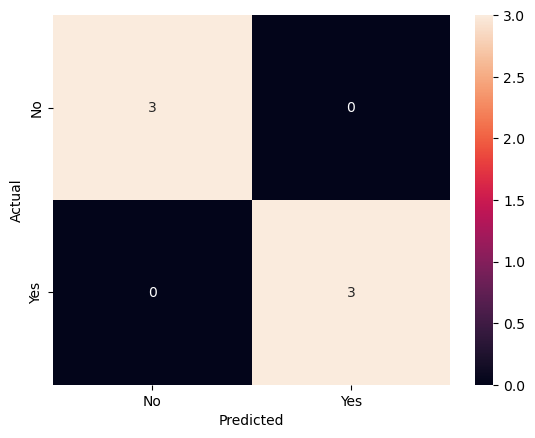

In [66]:
cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()